# ``meshlab`` - Tutorial 3

**Internal flow in a bent channel**


## 1. Import packages
---


In [9]:
import numpy as np
import matplotlib.pyplot as plt

from meshlab.core import Mesh, Curve, Contour, Front
from meshlab.operations import (
    insert_contour, initialize_front, compute_normals, advance_front,
    compute_angles, smooth_normals,
)
from meshlab.utils import plot_mesh

## 2. Geometries definition
---


Inlet, outlet and walls


In [10]:
# Geometric parameters
points_per_segment = 21

# Clockwise contour: wall normals point into the fluid
# ---
inlet = Curve("inlet", [[0.0, 0.0], [0.0, 1.0]])

# ---
inner_points = np.vstack((
    np.linspace([0.0, 1.0], [3.0, 1.0], points_per_segment, endpoint=False),
    np.linspace([3.0, 1.0], [3.0, 4.0], points_per_segment),
))
inner_wall = Curve("inner_wall", inner_points)

# ---
outlet = Curve("outlet", [[3.0, 4.0], [4.0, 4.0]])

# ---
outer_points = np.vstack((
    np.linspace([4.0, 4.0], [4.0, 0.0], points_per_segment, endpoint=False),
    np.linspace([4.0, 0.0], [0.0, 0.0], points_per_segment),
))
outer_wall = Curve("outer_wall", outer_points)

# Define contour
channel = Contour("channel", [inlet, inner_wall, outlet, outer_wall])

## 3. Creating mesh surfaces
---


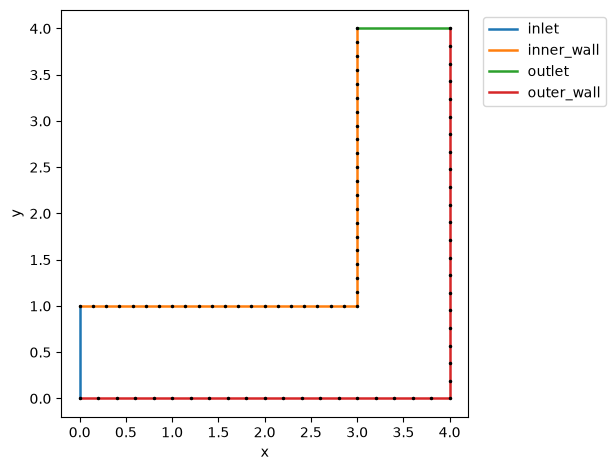

In [11]:
# 2D mesh definition
mesh = Mesh(dim=2)

# Insert contour
insert_contour(mesh, channel)

figure, ax = plot_mesh(mesh, show=False)

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()

plt.show()

## 4. Initialize fronts
---


In [12]:
# Layer parameters
num_layers = 4
height = 0.025
growth_rate = 1.10
smooth_steps = 5
relaxation = 1.0

# Front definitions
inner_front = Front("inner_front", int_dtype=mesh.int_dtype)
outer_front = Front("outer_front", int_dtype=mesh.int_dtype)

# Inlet and outlet guide the endpoints without generating layers
initialize_front(mesh, inner_front, curves=["inner_wall"], guides=["inlet", "outlet"])
initialize_front(mesh, outer_front, curves=["outer_wall"], guides=["inlet", "outlet"])

## 5. Growing boundary layers
---


First layer


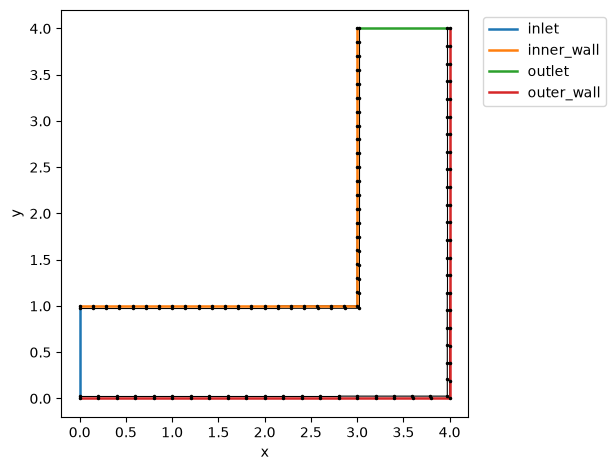

In [ ]:
for front in [inner_front, outer_front]:
    normals = compute_normals(mesh, front, method="bisector")

    rotation = np.zeros(len(normals), dtype=mesh.float_dtype)
    for _ in range(smooth_steps):
        normals, step_rotation = smooth_normals(mesh, front, normals, relaxation)
        rotation += step_rotation

    angles = compute_angles(mesh, front)
    # Same empirical height correction used in Tutorial 2
    heights = height / np.sin(angles / 2 + np.abs(rotation))
    advance_front(mesh, front, normals, heights)

figure, ax = plot_mesh(mesh, show=False)

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()

plt.show()

Additional layers


In [14]:
h = height
for _ in range(num_layers - 1):
    h *= growth_rate
    for front in [inner_front, outer_front]:
        normals = compute_normals(mesh, front, method="bisector")

        rotation = np.zeros(len(normals), dtype=mesh.float_dtype)
        for _ in range(smooth_steps):
            normals, step_rotation = smooth_normals(mesh, front, normals, relaxation)
            rotation += step_rotation

        angles = compute_angles(mesh, front)
        heights = h / np.sin(angles / 2 + np.abs(rotation))
        advance_front(mesh, front, normals, heights)

## 6. Visualize mesh
---


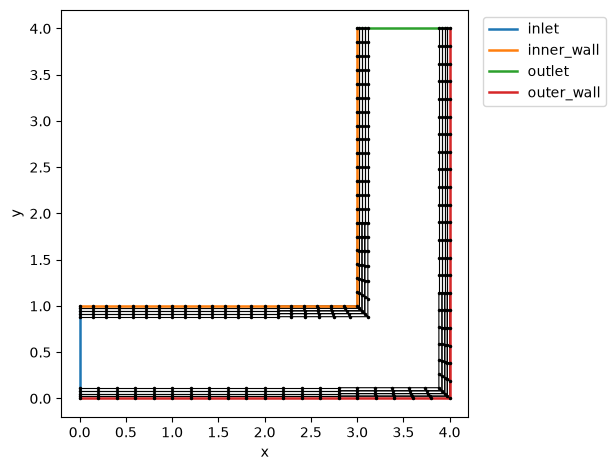

In [15]:
# The central region remains unmeshed
figure, ax = plot_mesh(mesh, show=False)

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()

plt.show()